In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 48.0 MB/s  0:00:02


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from termcolor import colored
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler

# **Load Data (Dataset MOTSS)**

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [ ]:
# Lokasi dataset hasil pipeline MOTSS di Google Drive
folder_drive = '/content/drive/MyDrive/dataset/'

# Nama file output MOTSS
dataset_file = 'dataset_pipeline_penelitian_utama.xlsx'

In [ ]:
pd.set_option('display.max_rows', 10)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Membaca dataset hasil MOTSS
print(f"Attempting to read file from: {folder_drive + dataset_file}")
dataset = pd.read_excel(folder_drive + dataset_file)

print("Dataset MOTSS:", dataset.shape)
display(dataset.head())

Attempting to read file from: /content/drive/MyDrive/dataset/dataset_pipeline_penelitian_utama.xlsx
Dataset MOTSS: (774, 30)


,year,district,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day
0,2023,Kabupaten Purwakarta,Jatiluhur,50.300,41.700,0.068,0.086,554.000,28,0,26.701,111.000,80.622,363.000,3,2,22,2230.000,4.183,1526.800,0,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432
1,2023,Kabupaten Purwakarta,Sukasari,50.300,41.700,0.068,0.086,699.000,73,0,22.824,220.000,81.016,51.000,1,2,26,50.000,5.743,2096.200,0,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869
2,2023,Kabupaten Purwakarta,Maniis,50.300,41.700,0.068,0.086,2302.000,91,0,26.713,223.000,80.208,240.000,6,14,59,2680.000,4.183,1526.800,0,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128
3,2023,Kabupaten Purwakarta,Tegal Waru,50.300,41.700,0.068,0.086,1711.000,407,0,26.856,1155.000,80.225,487.000,3,8,222,2012.000,4.183,1526.800,0,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188
4,2023,Kabupaten Purwakarta,Plered,50.300,41.700,0.068,0.086,963.000,46,0,26.687,257.000,80.208,297.000,3,5,16,500.000,4.183,1526.800,0,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353


# **Pre-Processing Data**

In [ ]:
# Penyesuaian dataset MOTSS
# Dataset MOTSS menggunakan kolom 'district' dan 'subdistrict',
# bukan 'district/city' seperti dataset pada notebook asli.
df = dataset.copy()

for col in ['district', 'subdistrict']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

print("Kolom wilayah tersedia:", [c for c in ['district', 'subdistrict'] if c in df.columns])
print("Jumlah district:", df['district'].nunique() if 'district' in df.columns else 'Tidak tersedia')

Kolom wilayah tersedia: ['district', 'subdistrict']
Jumlah district: 9


In [ ]:
# Konversi kolom selain identitas wilayah menjadi numerik jika memungkinkan
identifier_cols = ['district', 'subdistrict']
for col in df.columns:
    if col not in identifier_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print("Tipe data setelah pemeriksaan:")
display(df.dtypes)

Tipe data setelah pemeriksaan:


,0
year,int64
district,object
subdistrict,object
Manure_per_animal_sapiPerah,float64
Manure_per_animal_sapiPotong,float64
...,...
total_manure_potential_day_chicken_kg,float64
crude_oil_price_usd_avg,float64
usd_idr_avg,float64
energy_price_proxy_idr,float64


In [ ]:
# Validasi kolom populasi ternak yang tersedia pada dataset MOTSS
cols_check = [
    col for col in
    ['beef_cattle', 'dairy_cattle', 'layer_chickens', 'broiler_chickens']
    if col in df.columns
]

print("Kolom populasi ternak yang diperiksa:", cols_check)
print("Missing value pada kolom tersebut:")
display(df[cols_check].isna().sum())

# Dataset hasil MOTSS seharusnya sudah melalui preprocessing.
# Baris hanya dihapus jika kolom populasi yang digunakan memang missing.
if cols_check:
    df = df.dropna(subset=cols_check).copy()

print("Shape setelah validasi:", df.shape)

Kolom populasi ternak yang diperiksa: ['beef_cattle', 'dairy_cattle', 'layer_chickens', 'broiler_chickens']
Missing value pada kolom tersebut:


,0
beef_cattle,0
dairy_cattle,0
layer_chickens,0
broiler_chickens,0


Shape setelah validasi: (774, 30)


In [ ]:
# Dataset MOTSS tidak memiliki kolom livestock_type.
# Kategori district diubah menjadi dummy seperti encoding kategorikal pada notebook asli.
if 'district' in df.columns:
    df = pd.get_dummies(
        df,
        columns=['district'],
        prefix='district',
        drop_first=False,
        dtype=int
    )

display(df.head())

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,554.000,28,0,26.701,111.000,80.622,363.000,3,2,22,2230.000,4.183,1526.800,0,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,699.000,73,0,22.824,220.000,81.016,51.000,1,2,26,50.000,5.743,2096.200,0,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,2302.000,91,0,26.713,223.000,80.208,240.000,6,14,59,2680.000,4.183,1526.800,0,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,1711.000,407,0,26.856,1155.000,80.225,487.000,3,8,222,2012.000,4.183,1526.800,0,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,963.000,46,0,26.687,257.000,80.208,297.000,3,5,16,500.000,4.183,1526.800,0,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1


In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,554.000,28,0,26.701,111.000,80.622,363.000,3,2,22,2230.000,4.183,1526.800,0,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,699.000,73,0,22.824,220.000,81.016,51.000,1,2,26,50.000,5.743,2096.200,0,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,2302.000,91,0,26.713,223.000,80.208,240.000,6,14,59,2680.000,4.183,1526.800,0,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,1711.000,407,0,26.856,1155.000,80.225,487.000,3,8,222,2012.000,4.183,1526.800,0,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,963.000,46,0,26.687,257.000,80.208,297.000,3,5,16,500.000,4.183,1526.800,0,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,1573.000,160,0,23.192,482.000,81.455,1038.000,5,22,34,1182.000,5.743,2096.200,0,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,2196.000,42,0,26.773,120.000,81.068,181.000,7,42,74,1792.000,4.183,1526.800,0,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,1708.000,31,1,24.573,98.000,79.852,256.000,4,19,21,407.000,5.743,2096.200,1,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,878.000,28,0,25.223,97.000,81.285,158.000,4,9,20,3571.000,4.561,1664.800,0,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


Imputation

In [ ]:
# Dataset yang digunakan adalah output akhir MOTSS dan sudah dibersihkan.
# Tidak dilakukan penggantian nilai 0 dengan rata-rata karena nilai 0
# pada populasi ternak/potensi dapat merupakan nilai yang valid.
print("Missing value sebelum modeling:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("Nilai nol pada kolom numerik (dipertahankan):")
display((df.select_dtypes(include=[np.number]) == 0).sum().sort_values(ascending=False).head(15))

Missing value sebelum modeling:


,0


Nilai nol pada kolom numerik (dipertahankan):


,0
district_Bandung Barat,726
district_Kabupaten Purwakarta,723
district_Kabupaten Bekasi,705
district_Kabupaten Ciamis,693
district_Kabupaten Bandung,681
...,...
dairy_cattle,576
layer_chickens,539
broiler_chickens,528
industrial_feed,516


In [ ]:
def grab_col_names(dataframe, cat_th=10, car_th=20):

    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]

    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and
                   dataframe[col].dtypes != "O"]

    cat_but_car = [col for col in dataframe.columns if dataframe[col].nunique() > car_th and
                   dataframe[col].dtypes == "O"]

    cat_cols = cat_cols + num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]

    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O"]
    num_cols = [col for col in num_cols if col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f'cat_cols: {len(cat_cols)}')
    print(f'num_cols: {len(num_cols)}')
    print(f'cat_but_car: {len(cat_but_car)}')
    print(f'num_but_cat: {len(num_but_cat)}')

    return cat_cols, num_cols, cat_but_car, num_but_cat


In [ ]:
cat_cols, num_cols, cat_but_car,  num_but_cat = grab_col_names(df)

Observations: 774
Variables: 38
cat_cols: 17
num_cols: 20
cat_but_car: 1
num_but_cat: 17


In [ ]:
cat_cols

['year',
 'Manure_per_animal_sapiPerah',
 'Manure_per_animal_sapiPotong',
 'manure_per_animal_chicken_layer',
 'manure_per_animal_chicken_potong',
 'crude_oil_price_usd_avg',
 'usd_idr_avg',
 'energy_price_proxy_idr',
 'district_Bandung Barat',
 'district_Bogor',
 'district_Cirebon',
 'district_Kabupaten Bandung',
 'district_Kabupaten Bekasi',
 'district_Kabupaten Ciamis',
 'district_Kabupaten Cianjur',
 'district_Kabupaten Kuningan',
 'district_Kabupaten Purwakarta']

In [ ]:
num_cols

['non_industrial_feed',
 'dairy_cattle',
 'beef_cattle',
 'average_temperature_per_district',
 'total_ekor_sapi_daging',
 'humidity',
 'mixed_feed',
 'layer_chickens',
 'broiler_chickens',
 'industrial_feed',
 'total_ekor_ayam_petelur',
 'Average_daily_rainfall',
 'total_rainfall',
 'total_ekor_sapi_perah',
 'total_manure_potential_year_cattle_ton',
 'total_manure_potential_day_cattle_kg',
 'total_ekor_ayam_pedaging',
 'total_manure_potential_year_chicken_ton',
 'total_manure_potential_day_chicken_kg',
 'Potential_biogas_day']

In [ ]:
cat_but_car

['subdistrict']

In [ ]:
num_but_cat

['year',
 'Manure_per_animal_sapiPerah',
 'Manure_per_animal_sapiPotong',
 'manure_per_animal_chicken_layer',
 'manure_per_animal_chicken_potong',
 'crude_oil_price_usd_avg',
 'usd_idr_avg',
 'energy_price_proxy_idr',
 'district_Bandung Barat',
 'district_Bogor',
 'district_Cirebon',
 'district_Kabupaten Bandung',
 'district_Kabupaten Bekasi',
 'district_Kabupaten Ciamis',
 'district_Kabupaten Cianjur',
 'district_Kabupaten Kuningan',
 'district_Kabupaten Purwakarta']

In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,554.000,28,0,26.701,111.000,80.622,363.000,3,2,22,2230.000,4.183,1526.800,0,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,699.000,73,0,22.824,220.000,81.016,51.000,1,2,26,50.000,5.743,2096.200,0,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,2302.000,91,0,26.713,223.000,80.208,240.000,6,14,59,2680.000,4.183,1526.800,0,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,1711.000,407,0,26.856,1155.000,80.225,487.000,3,8,222,2012.000,4.183,1526.800,0,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,963.000,46,0,26.687,257.000,80.208,297.000,3,5,16,500.000,4.183,1526.800,0,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,1573.000,160,0,23.192,482.000,81.455,1038.000,5,22,34,1182.000,5.743,2096.200,0,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,2196.000,42,0,26.773,120.000,81.068,181.000,7,42,74,1792.000,4.183,1526.800,0,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,1708.000,31,1,24.573,98.000,79.852,256.000,4,19,21,407.000,5.743,2096.200,1,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,878.000,28,0,25.223,97.000,81.285,158.000,4,9,20,3571.000,4.561,1664.800,0,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


In [ ]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    iqr = quartile3 - quartile1

    # If IQR is 0, we cannot define meaningful outlier limits
    if iqr == 0:
        return None, None

    up_limit = quartile3 + 1.5 * iqr
    low_limit = quartile1 - 1.5 * iqr
    return low_limit, up_limit


In [ ]:

def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)

    # No valid thresholds (e.g., IQR = 0), treat as "no outlier handling"
    if low_limit is None or up_limit is None:
        return False

    return dataframe[
        (dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)
    ].any(axis=None)

In [ ]:

def replace_with_thresholds(dataframe, variable):
    low_limit, up_limit = outlier_thresholds(dataframe, variable)

    # Skip if thresholds are not valid
    if low_limit is None or up_limit is None:
        # print(f"Skip capping for {variable}: IQR = 0 (zero-inflated or constant).")
        return

    dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
    dataframe.loc[dataframe[variable] > up_limit, variable] = up_limit

In [ ]:
for col in num_cols:
    print(col, check_outlier(df, col))

non_industrial_feed True
dairy_cattle True
beef_cattle False
average_temperature_per_district True
total_ekor_sapi_daging True
humidity False
mixed_feed True
layer_chickens True
broiler_chickens True
industrial_feed True
total_ekor_ayam_petelur True
Average_daily_rainfall True
total_rainfall True
total_ekor_sapi_perah True
total_manure_potential_year_cattle_ton True
total_manure_potential_day_cattle_kg True
total_ekor_ayam_pedaging True
total_manure_potential_year_chicken_ton True
total_manure_potential_day_chicken_kg True
Potential_biogas_day True


In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,554.000,28,0,26.701,111.000,80.622,363.000,3,2,22,2230.000,4.183,1526.800,0,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,699.000,73,0,22.824,220.000,81.016,51.000,1,2,26,50.000,5.743,2096.200,0,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,2302.000,91,0,26.713,223.000,80.208,240.000,6,14,59,2680.000,4.183,1526.800,0,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,1711.000,407,0,26.856,1155.000,80.225,487.000,3,8,222,2012.000,4.183,1526.800,0,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,963.000,46,0,26.687,257.000,80.208,297.000,3,5,16,500.000,4.183,1526.800,0,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,1573.000,160,0,23.192,482.000,81.455,1038.000,5,22,34,1182.000,5.743,2096.200,0,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,2196.000,42,0,26.773,120.000,81.068,181.000,7,42,74,1792.000,4.183,1526.800,0,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,1708.000,31,1,24.573,98.000,79.852,256.000,4,19,21,407.000,5.743,2096.200,1,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,878.000,28,0,25.223,97.000,81.285,158.000,4,9,20,3571.000,4.561,1664.800,0,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


In [ ]:
for col in num_cols:
    if check_outlier(df, col):
        replace_with_thresholds(df, col)

/tmp/ipykernel_522/603271681.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-1.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
/tmp/ipykernel_522/603271681.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-4.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
/tmp/ipykernel_522/603271681.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-28.125' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
/tmp/ipykerne

In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,385.625,2.500,0,26.701,111.000,80.622,332.500,3,2.000,22.000,2230.000,4.183,1526.800,0.000,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,385.625,2.500,0,22.824,220.000,81.016,51.000,1,2.000,26.000,50.000,5.743,2096.200,0.000,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,385.625,2.500,0,26.713,223.000,80.208,240.000,5,7.500,46.875,2680.000,4.183,1526.800,0.000,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,385.625,2.500,0,26.856,1155.000,80.225,332.500,3,7.500,46.875,2012.000,4.183,1526.800,0.000,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,385.625,2.500,0,26.687,257.000,80.208,297.000,3,5.000,16.000,500.000,4.183,1526.800,0.000,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,385.625,2.500,0,23.192,482.000,81.455,332.500,5,7.500,34.000,1182.000,5.743,2096.200,0.000,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,385.625,2.500,0,26.773,120.000,81.068,181.000,5,7.500,46.875,1792.000,4.183,1526.800,0.000,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,385.625,2.500,1,24.573,98.000,79.852,256.000,4,7.500,21.000,407.000,5.743,2096.200,1.000,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,385.625,2.500,0,25.223,97.000,81.285,158.000,4,7.500,20.000,3571.000,4.561,1664.800,0.000,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


In [ ]:
for col in num_cols:
    print(col, check_outlier(df, col))

non_industrial_feed False
dairy_cattle False
beef_cattle False
average_temperature_per_district False
total_ekor_sapi_daging False
humidity False
mixed_feed False
layer_chickens False
broiler_chickens False
industrial_feed False
total_ekor_ayam_petelur False
Average_daily_rainfall False
total_rainfall False
total_ekor_sapi_perah False
total_manure_potential_year_cattle_ton False
total_manure_potential_day_cattle_kg False
total_ekor_ayam_pedaging False
total_manure_potential_year_chicken_ton False
total_manure_potential_day_chicken_kg False
Potential_biogas_day False


In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,385.625,2.500,0,26.701,111.000,80.622,332.500,3,2.000,22.000,2230.000,4.183,1526.800,0.000,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,385.625,2.500,0,22.824,220.000,81.016,51.000,1,2.000,26.000,50.000,5.743,2096.200,0.000,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,385.625,2.500,0,26.713,223.000,80.208,240.000,5,7.500,46.875,2680.000,4.183,1526.800,0.000,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,385.625,2.500,0,26.856,1155.000,80.225,332.500,3,7.500,46.875,2012.000,4.183,1526.800,0.000,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,385.625,2.500,0,26.687,257.000,80.208,297.000,3,5.000,16.000,500.000,4.183,1526.800,0.000,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,385.625,2.500,0,23.192,482.000,81.455,332.500,5,7.500,34.000,1182.000,5.743,2096.200,0.000,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,385.625,2.500,0,26.773,120.000,81.068,181.000,5,7.500,46.875,1792.000,4.183,1526.800,0.000,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,385.625,2.500,1,24.573,98.000,79.852,256.000,4,7.500,21.000,407.000,5.743,2096.200,1.000,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,385.625,2.500,0,25.223,97.000,81.285,158.000,4,7.500,20.000,3571.000,4.561,1664.800,0.000,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


In [ ]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]

    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)

    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)

    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])

    print(missing_df, end="\n")

    if na_name:
        return na_columns

In [ ]:
missing_values_table(df)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [ ]:
df.head(9)

,year,subdistrict,Manure_per_animal_sapiPerah,Manure_per_animal_sapiPotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,Average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,Potential_biogas_day,district_Bandung Barat,district_Bogor,district_Cirebon,district_Kabupaten Bandung,district_Kabupaten Bekasi,district_Kabupaten Ciamis,district_Kabupaten Cianjur,district_Kabupaten Kuningan,district_Kabupaten Purwakarta
0,2023,Jatiluhur,50.300,41.700,0.068,0.086,385.625,2.500,0,26.701,111.000,80.622,332.500,3,2.000,22.000,2230.000,4.183,1526.800,0.000,1689.476,4628.700,10060.000,371.132,1016.800,68.106,14310.540,974634.067,2.432,0,0,0,0,0,0,0,0,1
1,2023,Sukasari,50.300,41.700,0.068,0.086,385.625,2.500,0,22.824,220.000,81.016,51.000,1,2.000,26.000,50.000,5.743,2096.200,0.000,3348.510,9174.000,10000.000,315.141,863.400,68.106,14310.540,974634.067,2.869,0,0,0,0,0,0,0,0,1
2,2023,Maniis,50.300,41.700,0.068,0.086,385.625,2.500,0,26.713,223.000,80.208,240.000,5,7.500,46.875,2680.000,4.183,1526.800,0.000,3394.171,9299.100,148510.000,4728.246,12954.100,68.106,14310.540,974634.067,22.128,0,0,0,0,0,0,0,0,1
3,2023,Tegal Waru,50.300,41.700,0.068,0.086,385.625,2.500,0,26.856,1155.000,80.225,332.500,3,7.500,46.875,2012.000,4.183,1526.800,0.000,17579.678,48163.500,14980.000,520.160,1425.096,68.106,14310.540,974634.067,10.188,0,0,0,0,0,0,0,0,1
4,2023,Plered,50.300,41.700,0.068,0.086,385.625,2.500,0,26.687,257.000,80.208,297.000,3,5.000,16.000,500.000,4.183,1526.800,0.000,3911.669,10716.900,11250.000,365.548,1001.500,68.106,14310.540,974634.067,3.353,0,0,0,0,0,0,0,0,1
5,2023,Sukatani,50.300,41.700,0.068,0.086,385.625,2.500,0,23.192,482.000,81.455,332.500,5,7.500,34.000,1182.000,5.743,2096.200,0.000,7336.281,20099.400,112964.000,3575.277,9795.280,68.106,14310.540,974634.067,18.844,0,0,0,0,0,0,0,0,1
6,2023,Darangdan,50.300,41.700,0.068,0.086,385.625,2.500,0,26.773,120.000,81.068,181.000,5,7.500,46.875,1792.000,4.183,1526.800,0.000,1826.460,5004.000,132240.000,4195.491,11494.496,68.106,14310.540,974634.067,19.087,0,0,0,0,0,0,0,0,1
7,2023,Bojong,50.300,41.700,0.068,0.086,385.625,2.500,1,24.573,98.000,79.852,256.000,4,7.500,21.000,407.000,5.743,2096.200,1.000,1509.968,4136.900,68751.000,2168.196,5940.262,68.106,14310.540,974634.067,10.272,0,0,0,0,0,0,0,0,1
8,2023,Wanayasa,50.300,41.700,0.068,0.086,385.625,2.500,0,25.223,97.000,81.285,158.000,4,7.500,20.000,3571.000,4.561,1664.800,0.000,1476.389,4044.900,20540.000,733.383,2009.268,68.106,14310.540,974634.067,3.948,0,0,0,0,0,0,0,0,1


In [ ]:
# Keluarkan target dari daftar fitur numerik untuk keperluan ringkasan fitur
target_original_name = "Potential_biogas_day"
num_cols = [col for col in num_cols if col != target_original_name]

In [ ]:
# Editing of variable names.

df.columns = df.columns.str.replace(' ', '_')
df.columns = df.columns.str.replace('[^A-Za-z0-9_]+', '', regex=True)
df.columns = df.columns.str.lower()

In [ ]:
# Isi suhu kalau ada NaN (jaga-jaga saja)
if "average_temperature_per_district" in df.columns:
    df["average_temperature_per_district"] = df["average_temperature_per_district"].fillna(
        df["average_temperature_per_district"].median()
    )


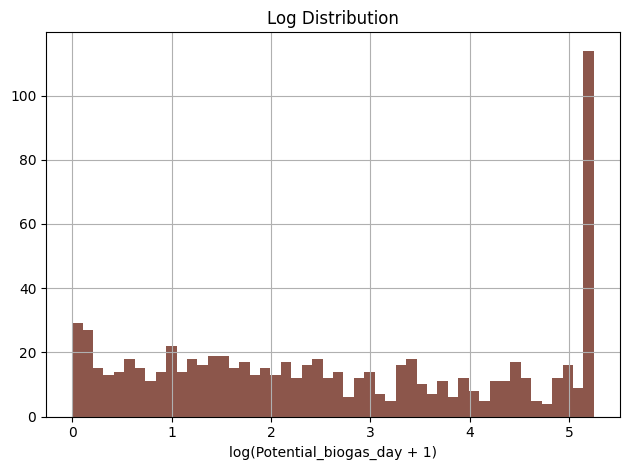

In [ ]:
palette = sns.color_palette("tab20")
idx = hash("log_potential_biogas_day") % len(palette)
color = palette[idx]

np.log1p(df['potential_biogas_day']).hist(
    bins=50,
    color=color
)

plt.xlabel("log(Potential_biogas_day + 1)")
plt.title("Log Distribution")
plt.tight_layout()
plt.show(block=True)

# **EDA (Exploratory Data Analysis)**

In [ ]:
# EDA menggunakan dataset MOTSS sebelum kolom year dikeluarkan dari fitur model.
# Data asli dipakai untuk ringkasan target dan wilayah agar tidak terpengaruh encoding/outlier handling.
eda_raw = dataset.copy()
eda_raw.columns = (
    eda_raw.columns.str.replace(' ', '_')
                    .str.replace('[^A-Za-z0-9_]+', '', regex=True)
                    .str.lower()
)
target_eda = 'potential_biogas_day'
eda_raw[target_eda] = pd.to_numeric(eda_raw[target_eda], errors='coerce')

print(f'Jumlah baris: {len(eda_raw):,}')
print(f'Jumlah kolom: {eda_raw.shape[1]}')
print(f'Tahun: {sorted(eda_raw["year"].dropna().unique().tolist())}')
print(f'Jumlah kabupaten/kota: {eda_raw["district"].nunique()}')
print(f'Jumlah kecamatan: {eda_raw["subdistrict"].nunique()}')
print(f'Duplikasi baris: {eda_raw.duplicated().sum()}')
print(f'Total missing value: {eda_raw.isna().sum().sum()}')


Jumlah baris: 774
Jumlah kolom: 30
Tahun: [2021, 2022, 2023]
Jumlah kabupaten/kota: 9
Jumlah kecamatan: 251
Duplikasi baris: 0
Total missing value: 0


count    774.000
mean      99.099
std      265.185
min        0.000
25%        2.213
50%       10.520
75%       77.183
max     2178.183

Jumlah target bernilai 0: 16 (2.07%)
Skewness target: 4.771


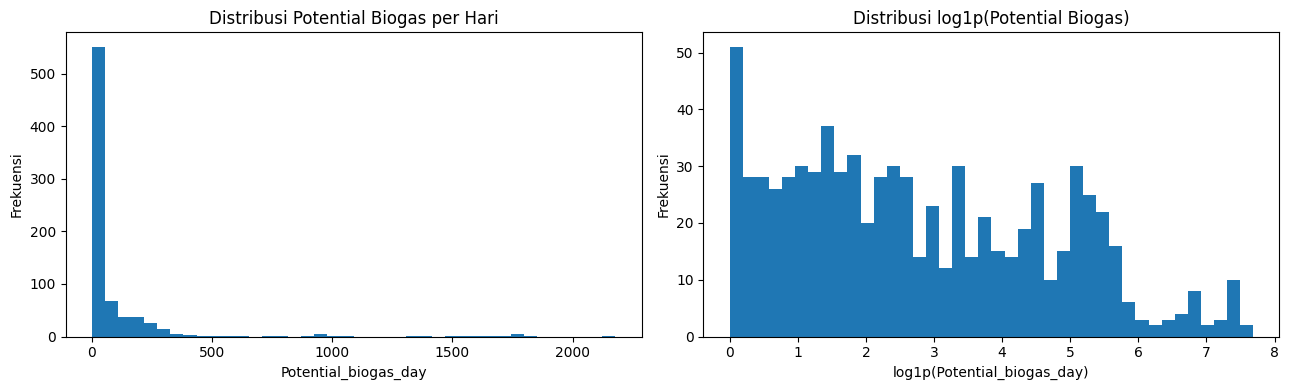

In [ ]:
# Ringkasan statistik target Y1 dan pemeriksaan nilai nol/skewness.
y_eda = eda_raw[target_eda].dropna()
print(y_eda.describe().to_string())
print(f'\nJumlah target bernilai 0: {(y_eda == 0).sum():,} ({(y_eda == 0).mean()*100:.2f}%)')
print(f'Skewness target: {y_eda.skew():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(y_eda, bins=40)
axes[0].set_title('Distribusi Potential Biogas per Hari')
axes[0].set_xlabel('Potential_biogas_day')
axes[0].set_ylabel('Frekuensi')
axes[1].hist(np.log1p(y_eda), bins=40)
axes[1].set_title('Distribusi log1p(Potential Biogas)')
axes[1].set_xlabel('log1p(Potential_biogas_day)')
axes[1].set_ylabel('Frekuensi')
plt.tight_layout()
plt.show()


,year,count,mean,median,std
0,2021,258,148.745,31.059,318.523
1,2022,258,117.613,15.862,288.743
2,2023,258,30.939,3.519,138.583


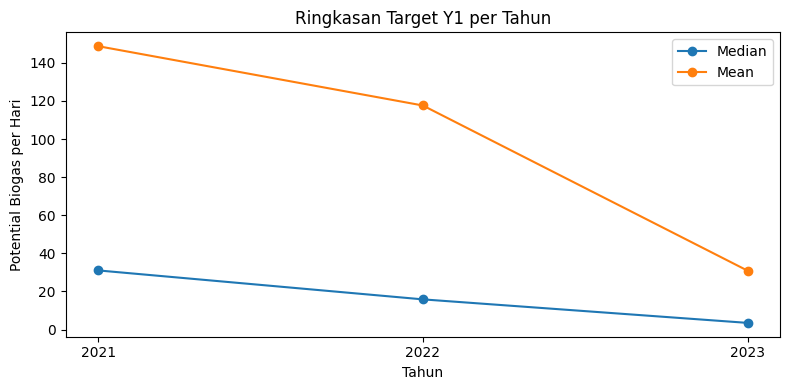

In [ ]:
# Ringkasan perubahan target berdasarkan tahun.
year_summary = (
    eda_raw.groupby('year')[target_eda]
    .agg(['count', 'mean', 'median', 'std'])
    .reset_index()
)
display(year_summary.round(3))

plt.figure(figsize=(8, 4))
plt.plot(year_summary['year'], year_summary['median'], marker='o', label='Median')
plt.plot(year_summary['year'], year_summary['mean'], marker='o', label='Mean')
plt.xlabel('Tahun')
plt.ylabel('Potential Biogas per Hari')
plt.title('Ringkasan Target Y1 per Tahun')
plt.xticks(year_summary['year'])
plt.legend()
plt.tight_layout()
plt.show()


,count,mean,median
district,,,
Bogor,120,115.438,90.989
Kabupaten Ciamis,81,369.049,81.519
Kabupaten Kuningan,96,62.927,15.953
Bandung Barat,48,171.106,14.099
Kabupaten Bandung,93,102.802,12.859
Kabupaten Cianjur,96,53.519,8.327
Cirebon,120,18.380,5.330
Kabupaten Purwakarta,51,28.984,4.198
Kabupaten Bekasi,69,4.651,1.881


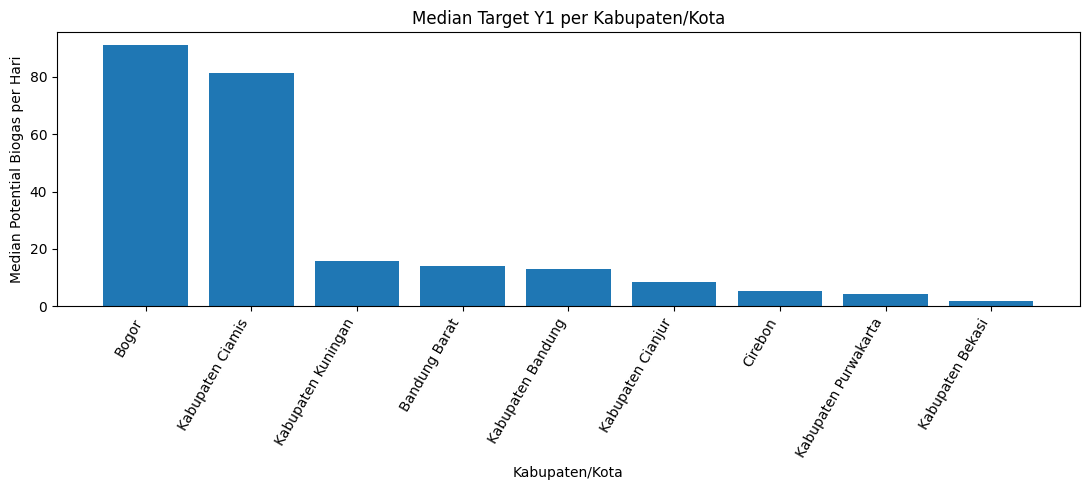

In [ ]:
# Perbandingan target antar kabupaten/kota (jumlah kategori relatif sedikit).
district_summary = (
    eda_raw.groupby('district')[target_eda]
    .agg(['count', 'mean', 'median'])
    .sort_values('median', ascending=False)
)
display(district_summary.round(3))

plt.figure(figsize=(11, 5))
plt.bar(district_summary.index, district_summary['median'])
plt.xticks(rotation=60, ha='right')
plt.xlabel('Kabupaten/Kota')
plt.ylabel('Median Potential Biogas per Hari')
plt.title('Median Target Y1 per Kabupaten/Kota')
plt.tight_layout()
plt.show()


Total kecamatan unik: 251


,subdistrict,jumlah_observasi
0,Pasawahan,6
1,Sukatani,6
2,Plered,6
3,Campaka,6
4,Cisarua,6
5,Pacet,6
6,Cibinong,6
7,Darangdan,3
8,Bojong,3
9,Wanayasa,3


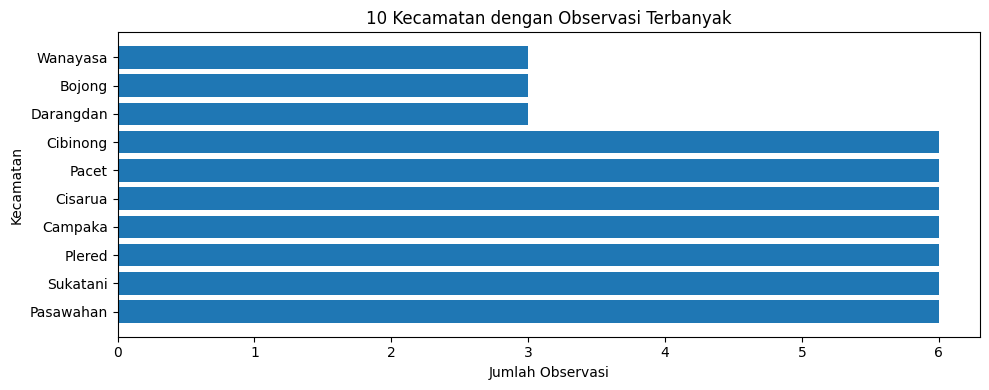

In [ ]:
# Distribusi unit wilayah: tampilkan 10 kecamatan dengan jumlah observasi terbanyak.
subdistrict_counts = eda_raw['subdistrict'].value_counts().head(10)
print(f'Total kecamatan unik: {eda_raw["subdistrict"].nunique()}')
display(subdistrict_counts.rename_axis('subdistrict').reset_index(name='jumlah_observasi'))

plt.figure(figsize=(10, 4))
plt.barh(subdistrict_counts.index, subdistrict_counts.values)
plt.xlabel('Jumlah Observasi')
plt.ylabel('Kecamatan')
plt.title('10 Kecamatan dengan Observasi Terbanyak')
plt.tight_layout()
plt.show()


12 fitur dengan korelasi absolut tertinggi terhadap target:


,correlation_with_target
total_manure_potential_day_chicken_kg,0.805
total_manure_potential_year_chicken_ton,0.805
total_ekor_ayam_pedaging,0.802
total_ekor_sapi_perah,0.549
total_manure_potential_day_cattle_kg,0.456
...,...
total_rainfall,0.305
average_daily_rainfall,0.305
average_temperature_per_district,-0.267
humidity,0.263


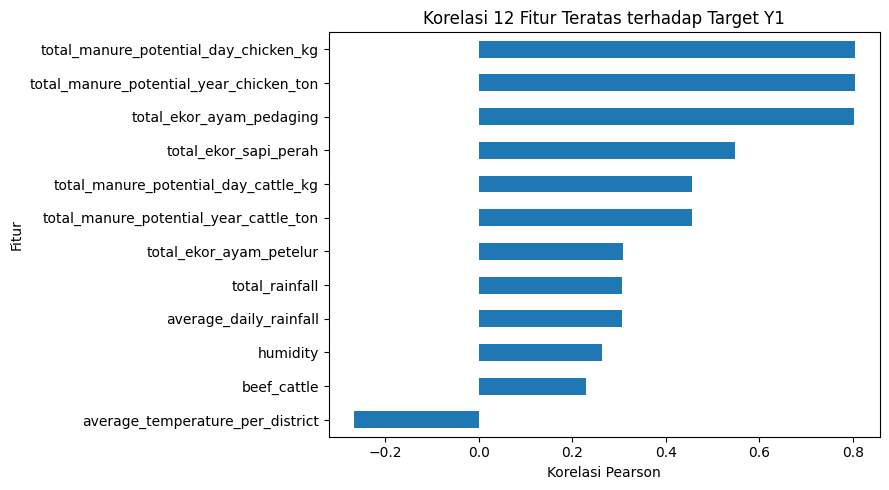

Catatan: korelasi tinggi perlu ditinjau secara konseptual, terutama variabel potensi manure yang mungkin berkaitan langsung secara perhitungan dengan target.


In [ ]:
# Korelasi numerik terhadap target sebagai pemeriksaan awal, bukan dasar otomatis menghapus fitur.
eda_numeric = eda_raw.select_dtypes(include=[np.number]).copy()
target_corr = (
    eda_numeric.corr(numeric_only=True)[target_eda]
    .drop(labels=[target_eda], errors='ignore')
    .dropna()
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print('12 fitur dengan korelasi absolut tertinggi terhadap target:')
display(target_corr.head(12).to_frame('correlation_with_target').round(3))

plt.figure(figsize=(9, 5))
target_corr.head(12).sort_values().plot(kind='barh')
plt.xlabel('Korelasi Pearson')
plt.ylabel('Fitur')
plt.title('Korelasi 12 Fitur Teratas terhadap Target Y1')
plt.tight_layout()
plt.show()

print('Catatan: korelasi tinggi perlu ditinjau secara konseptual, terutama variabel potensi manure yang mungkin berkaitan langsung secara perhitungan dengan target.')


In [ ]:
# Akhiri EDA. Tahun tetap tidak digunakan sebagai fitur model, mengikuti alur notebook dasar.
# Penghapusan dilakukan setelah EDA agar ringkasan temporal tetap dapat dianalisis.
df.drop(columns=['year'], inplace=True, errors='ignore')
print('Kolom year dihapus dari df untuk tahap modeling:', 'year' not in df.columns)


Kolom year dihapus dari df untuk tahap modeling: True


# **Scaler Data**

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Target tidak boleh ikut di-scale
target_col = "potential_biogas_day"
scaled_num_cols = [c for c in num_cols if c != target_col]

In [ ]:
scaler = MinMaxScaler()

In [ ]:
# Pertahankan MinMaxScaler seperti notebook asli, tetapi hanya untuk fitur.
# Target tetap dalam satuan aslinya agar inverse log1p pada evaluasi benar.
df[scaled_num_cols] = scaler.fit_transform(df[scaled_num_cols])

In [ ]:
df.head(10)


,subdistrict,manure_per_animal_sapiperah,manure_per_animal_sapipotong,manure_per_animal_chicken_layer,manure_per_animal_chicken_potong,non_industrial_feed,dairy_cattle,beef_cattle,average_temperature_per_district,total_ekor_sapi_daging,humidity,mixed_feed,layer_chickens,broiler_chickens,industrial_feed,total_ekor_ayam_petelur,average_daily_rainfall,total_rainfall,total_ekor_sapi_perah,total_manure_potential_year_cattle_ton,total_manure_potential_day_cattle_kg,total_ekor_ayam_pedaging,total_manure_potential_year_chicken_ton,total_manure_potential_day_chicken_kg,crude_oil_price_usd_avg,usd_idr_avg,energy_price_proxy_idr,potential_biogas_day,district_bandung_barat,district_bogor,district_cirebon,district_kabupaten_bandung,district_kabupaten_bekasi,district_kabupaten_ciamis,district_kabupaten_cianjur,district_kabupaten_kuningan,district_kabupaten_purwakarta
0,Jatiluhur,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.881,0.092,0.382,1.000,0.600,0.267,0.469,0.054,0.115,0.115,0.000,0.068,0.068,0.016,0.018,0.018,0.000,0.000,0.000,2.432,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
1,Sukasari,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.439,0.181,0.406,0.153,0.200,0.267,0.555,0.001,0.282,0.282,0.000,0.134,0.134,0.016,0.016,0.016,0.000,0.000,0.000,2.869,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
2,Maniis,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.882,0.184,0.357,0.722,1.000,1.000,1.000,0.065,0.115,0.115,0.000,0.136,0.136,0.235,0.235,0.235,0.000,0.000,0.000,22.128,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
3,Tegal Waru,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.899,0.952,0.358,1.000,0.600,1.000,1.000,0.049,0.115,0.115,0.000,0.703,0.703,0.024,0.026,0.026,0.000,0.000,0.000,10.188,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
4,Plered,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.880,0.212,0.357,0.893,0.600,0.667,0.341,0.012,0.115,0.115,0.000,0.156,0.156,0.018,0.018,0.018,0.000,0.000,0.000,3.353,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
5,Sukatani,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.481,0.397,0.432,1.000,1.000,1.000,0.725,0.029,0.282,0.282,0.000,0.293,0.293,0.179,0.178,0.178,0.000,0.000,0.000,18.844,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
6,Darangdan,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.889,0.099,0.409,0.544,1.000,1.000,1.000,0.043,0.115,0.115,0.000,0.073,0.073,0.210,0.208,0.208,0.000,0.000,0.000,19.087,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
7,Bojong,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.638,0.081,0.335,0.770,0.800,1.000,0.448,0.010,0.282,0.282,0.024,0.060,0.060,0.109,0.108,0.108,0.000,0.000,0.000,10.272,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
8,Wanayasa,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.712,0.080,0.422,0.475,0.800,1.000,0.427,0.086,0.155,0.155,0.000,0.059,0.059,0.033,0.036,0.036,0.000,0.000,0.000,3.948,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
9,Kiarapedes,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.873,0.085,0.397,0.770,1.000,1.000,0.981,0.206,0.115,0.115,0.073,0.065,0.065,0.040,0.050,0.050,0.000,0.000,0.000,5.938,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000


# **Modeling**

In [ ]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from datetime import datetime

from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn import metrics

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Target utama hasil MOTSS (Y1)
y = df["potential_biogas_day"]

# Drop kolom yang tidak menjadi prediktor:
# - target itu sendiri
# - subdistrict (identifier berkardinalitas tinggi), mengikuti pendekatan notebook asli
drop_cols = [
    "potential_biogas_day",
    "subdistrict"
]

X = df.drop(columns=drop_cols, errors='ignore')

# Pastikan semua fitur yang masuk ke 11 model bersifat numerik
X = X.select_dtypes(include=[np.number]).copy()

# Split data tetap mengikuti notebook asli: random 80:20, random_state=42
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Log-transform target untuk training, sesuai notebook asli
y_train_log = np.log1p(y_train_raw)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Target:", y.name)
print("Rentang target:", y.min(), "hingga", y.max())

# =========================================================
# 2. DEFINE MODELS (DIPERTAHANKAN DARI NOTEBOOK ASLI)
# =========================================================
models = [
    ('LR',        LinearRegression()),
    ("Ridge",     Ridge()),
    ("Lasso",     Lasso()),
    ("ElasticNet",ElasticNet(max_iter=10000)),
    ('KNN',       KNeighborsRegressor()),
    ('CART',      DecisionTreeRegressor()),
    ('RF',        RandomForestRegressor()),
    ('GBM',       GradientBoostingRegressor(
                     loss="huber",
                     alpha=0.9,
                     n_estimators=800,
                     learning_rate=0.03,
                     max_depth=3,
                     min_samples_leaf=10,
                     subsample=0.8,
                     max_features=0.8,
                     random_state=42
                 )),
    ("XGBoost",   XGBRegressor(objective='reg:squarederror')),
    ("LightGBM",  LGBMRegressor()),
    ("CatBoost",  CatBoostRegressor(verbose=False))
]

k_candidates = [5, 6, 7, 8, 10]

# =========================================================
# 3. CROSS VALIDATION LOOP (DIPERTAHANKAN)
# =========================================================
r2_cv_scores = []
r2_scores = []
mae_scores = []
mse_scores = []
execution_times = []
model_names = []
best_k_list = []
k_records = []

for name, regressor in models:
    print(f"\n==================== {name} ====================")
    start_time = time.time()

    local_k_candidates = k_candidates.copy()
    np.random.shuffle(local_k_candidates)

    k_score_list = []

    for k in local_k_candidates:
        kf = KFold(n_splits=k, shuffle=True, random_state=42)

        r2_cv = cross_val_score(
            regressor, X_train, y_train_log,
            cv=kf,
            scoring="r2",
            n_jobs=1
        ).mean()

        k_score_list.append((k, r2_cv))
        k_records.append({"Model": name, "K": k, "R2_CV": r2_cv})

    best_k, best_cv_r2 = max(k_score_list, key=lambda x: x[1])
    print(f"Best K = {best_k} | R² CV (log) = {best_cv_r2:.4f}")

    best_k_list.append(best_k)
    r2_cv_scores.append(best_cv_r2)
    model_names.append(name)

    regressor.fit(X_train, y_train_log)

    y_pred_log = regressor.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)

    r2  = metrics.r2_score(y_test_raw, y_pred_real)
    mae = metrics.mean_absolute_error(y_test_raw, y_pred_real)
    mse = metrics.mean_squared_error(y_test_raw, y_pred_real)

    r2_scores.append(r2)
    mae_scores.append(mae)
    mse_scores.append(mse)

    execution_times.append(time.time() - start_time)

# =========================================================
# 4. RESULT TABLE
# =========================================================
results_df = pd.DataFrame({
    'Model': model_names,
    'Best_K': best_k_list,
    'R2_CV_log': r2_cv_scores,
    'R^2 Test (real)': r2_scores,
    'MAE': mae_scores,
    'MSE': mse_scores,
    'Execution Time (s)': execution_times
}).sort_values(by="R^2 Test (real)", ascending=False).reset_index(drop=True)

print("\n===== FINAL RESULTS =====")
print(results_df)

# Save results to Excel


X_train: (619, 35) | X_test: (155, 35)
Target: potential_biogas_day
Rentang target: 0.0 hingga 189.63666257752334

==================== LR ====================
Best K = 5 | R² CV (log) = 0.8198

==================== Ridge ====================
Best K = 5 | R² CV (log) = 0.8194

==================== Lasso ====================
Best K = 5 | R² CV (log) = -0.0040

==================== ElasticNet ====================
Best K = 5 | R² CV (log) = -0.0040

==================== KNN ====================
Best K = 5 | R² CV (log) = 0.8618

==================== CART ====================
Best K = 10 | R² CV (log) = 0.9141

==================== RF ====================
Best K = 10 | R² CV (log) = 0.9515

==================== GBM ====================
Best K = 7 | R² CV (log) = 0.9528

==================== XGBoost ====================
Best K = 10 | R² CV (log) = 0.9579

==================== LightGBM ====================
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 

In [ ]:
import os
os.makedirs("/content/drive/MyDrive/dataset/hasil_pso", exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"/content/drive/MyDrive/dataset/hasil_pso/cv_results_baseline_{timestamp}.xlsx"
results_df.to_excel(filename, index=False)
print(f"\n📁 Baseline CV results saved to: {filename}")


📁 Baseline CV results saved to: /content/drive/MyDrive/dataset/hasil_pso/cv_results_baseline_20261118_203602.xlsx


# **Tuning with PSO (Particle Swarm Optimization) - Target Y1 MOTSS**

In [ ]:
import numpy as np
import pandas as pd
import time
from datetime import datetime

from sklearn.model_selection import KFold, train_test_split, cross_val_score
from sklearn.metrics import make_scorer, r2_score, mean_squared_error, mean_absolute_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import os
import joblib
from pathlib import Path

y_train_log = np.log1p(y_train_raw)
y_test_true = y_test_raw   # untuk evaluasi real-scale

# =========================================================
# 2. MODEL DEFINITIONS
# =========================================================
models = [
    ("LR",        LinearRegression()),
    ("Ridge",     Ridge()),
    ("Lasso",     Lasso()),
    ("ElasticNet",ElasticNet(max_iter=10000)),
    ("KNN",       KNeighborsRegressor()),
    ("CART",      DecisionTreeRegressor(random_state=42)),
    ("RF",        RandomForestRegressor(random_state=42)),
    ("GBM",       GradientBoostingRegressor(random_state=42)),
    ("XGBoost",   XGBRegressor(objective="reg:squarederror", random_state=42)),
    ("LightGBM",  LGBMRegressor(random_state=42)),
    ("CatBoost",  CatBoostRegressor(verbose=False, random_state=42)),
]

# =========================================================
# 3. PSO SEARCH SPACES
# =========================================================
pso_search_spaces = {
    "LR": {},

    "Ridge": {
        "alpha": (0.0001, 10.0, float)
    },

    "Lasso": {
        "alpha": (0.0001, 5.0, float)
    },

    "ElasticNet": {
        "alpha": (0.0001, 5.0, float),
        "l1_ratio": (0.0, 1.0, float)
    },

    "KNN": {
        "n_neighbors": (1, 50, int),
        "weights": (0, 1, int)
    },

    "CART": {
        "max_depth": (1, 30, int),
        "min_samples_split": (2, 20, int),
        "min_samples_leaf": (1, 10, int)
    },

    "RF": {
        "n_estimators": (50, 300, int),
        "max_depth": (3, 20, int),
        "min_samples_split": (2, 10, int)
    },

    "GBM": {
        "n_estimators": (50, 300, int),
        "learning_rate": (0.01, 0.2, float),
        "max_depth": (2, 10, int)
    },

    "XGBoost": {
        "n_estimators": (50, 300, int),
        "learning_rate": (0.01, 0.2, float),
        "max_depth": (3, 12, int),
        "subsample": (0.5, 1.0, float)
    },

    "LightGBM": {
        "n_estimators": (50, 300, int),
        "learning_rate": (0.01, 0.2, float),
        "num_leaves": (31, 255, int),
        "max_depth": (-1, 15, int)
    },

    "CatBoost": {
        "depth": (4, 10, int),
        "learning_rate": (0.01, 0.2, float),
        "n_estimators": (100, 500, int)
    }
}

# =========================================================
# 4. REAL-SCALE R² Scorer
# =========================================================
def r2_real_from_log(estimator, X_val, y_log_val):
    y_pred_log = estimator.predict(X_val)
    y_pred_real = np.expm1(y_pred_log)
    y_true_real = np.expm1(y_log_val)
    return r2_score(y_true_real, y_pred_real)

real_r2_scorer = r2_real_from_log  # callable scorer: (estimator, X, y_log)

# =========================================================
# 5. POSITION → PARAM MAPPER (PSO)
# =========================================================
def position_to_params(position, param_space, model_name=None):
    params = {}
    for i, (name, (low, high, ptype)) in enumerate(param_space.items()):
        val = position[i]

        if ptype is int:
            val = int(round(val))
        else:
            val = float(val)

        val = max(low, min(high, val))

        if name == "weights":
            val = "uniform" if int(round(val)) == 0 else "distance"

        if model_name == "LightGBM" and name == "max_depth":
            if val <= 0:
                val = -1

        params[name] = val

    return params

# =========================================================
# 6. PSO OPTIMIZER
# =========================================================
def pso_optimize_model(model_name,
                       model_cls,
                       base_model,
                       param_space,
                       X,
                       y_log,
                       k=5,
                       n_particles=10,
                       n_iterations=20,
                       w=0.7, c1=1.5, c2=1.5,
                       random_state=42):

    if len(param_space) == 0:
        base_model.fit(X, y_log)
        return base_model, {}, 0.0

    np.random.seed(random_state)
    dim = len(param_space)

    lows = np.array([v[0] for v in param_space.values()], dtype=float)
    highs = np.array([v[1] for v in param_space.values()], dtype=float)

    positions = lows + (highs - lows) * np.random.rand(n_particles, dim)
    velocities = np.zeros_like(positions)

    personal_best_positions = positions.copy()
    personal_best_scores = np.full(n_particles, -np.inf)

    global_best_position = positions[0].copy()
    global_best_score = -np.inf

    kf = KFold(n_splits=k, shuffle=True, random_state=42)

    for it in range(n_iterations):

        for i in range(n_particles):
            params = position_to_params(positions[i], param_space, model_name=model_name)

            model = model_cls(**{**base_model.get_params(), **params})

            scores = cross_val_score(
                model,
                X,
                y_log,
                cv=kf,
                scoring=real_r2_scorer,
                n_jobs=-1
            )
            score_mean = scores.mean()

            if np.isnan(score_mean):
                score_mean = -1e6

            if score_mean > personal_best_scores[i]:
                personal_best_scores[i] = score_mean
                personal_best_positions[i] = positions[i].copy()

            if score_mean > global_best_score:
                global_best_score = score_mean
                global_best_position = positions[i].copy()

        r1, r2 = np.random.rand(), np.random.rand()

        velocities = (
            w * velocities +
            c1 * r1 * (personal_best_positions - positions) +
            c2 * r2 * (global_best_position - positions)
        )
        positions = positions + velocities
        positions = np.maximum(positions, lows)
        positions = np.minimum(positions, highs)

    best_params = position_to_params(global_best_position, param_space, model_name=model_name)
    best_model = model_cls(**{**base_model.get_params(), **best_params})
    best_model.fit(X, y_log)

    return best_model, best_params, global_best_score


# =========================================================
# 7. RUN PSO FOR ALL MODELS + SAVE BEST MODELS
# =========================================================

# Direktori penyimpanan
output_dir = Path("/content/drive/MyDrive/dataset/hasil_pso")
model_dir = output_dir / "best_models"

output_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

pso_results = []

# Menyimpan informasi best overall model berdasarkan CV R2
best_overall_score = -np.inf
best_overall_model = None
best_overall_info = None

for name, regressor in models:
    print(f"\n===== {name} - PSO Tuning =====")

    if name not in pso_search_spaces:
        print(f"→ Skip for {name}")
        continue

    param_space = pso_search_spaces[name]
    model_cls = regressor.__class__
    best_k = 5

    start_time = time.time()

    best_model, best_params, cv_best_r2 = pso_optimize_model(
        model_name=name,
        model_cls=model_cls,
        base_model=regressor,
        param_space=param_space,
        X=X_train,
        y_log=y_train_log,
        k=best_k,
        n_particles=10,
        n_iterations=20,
        random_state=42
    )

    exec_time = time.time() - start_time

    # =====================================================
    # EVALUATION
    # =====================================================
    y_pred_log = best_model.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)

    mse = mean_squared_error(y_test_true, y_pred_real)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_true, y_pred_real)
    mae = mean_absolute_error(y_test_true, y_pred_real)

    print(f"  CV best R² (real scale): {cv_best_r2:.4f}")
    print(f"  TEST R² (real scale)   : {r2:.4f}")
    print(f"  Best Params: {best_params}")

    # =====================================================
    # SAVE BEST MODEL FOR EACH ALGORITHM
    # =====================================================
    model_filename = f"best_model_{name}.joblib"
    model_path = model_dir / model_filename

    model_bundle = {
        "model": best_model,
        "model_name": name,
        "best_params": best_params,
        "cv_best_r2": cv_best_r2,
        "test_r2": r2,
        "target_transform": "log1p",
        "prediction_inverse_transform": "expm1"
    }

    joblib.dump(model_bundle, model_path)

    print(f"  Model saved: {model_path}")

    # =====================================================
    # STORE RESULTS
    # =====================================================
    pso_results.append({
        "Model": name,
        "K (CV folds)": best_k,
        "CV Best R2 (real)": cv_best_r2,
        "R2 Test (real)": r2,
        "RMSE Test": rmse,
        "MAE Test": mae,
        "MSE Test": mse,
        "Best Params": str(best_params),
        "Execution Time (s)": exec_time,
        "Model Path": str(model_path)
    })

    # =====================================================
    # SELECT BEST OVERALL MODEL
    # Based on CV R2, not TEST R2
    # =====================================================
    if cv_best_r2 > best_overall_score:
        best_overall_score = cv_best_r2
        best_overall_model = best_model

        best_overall_info = {
            "model_name": name,
            "best_params": best_params,
            "cv_best_r2": cv_best_r2,
            "test_r2": r2,
            "rmse": rmse,
            "mae": mae,
            "mse": mse,
            "target_transform": "log1p",
            "prediction_inverse_transform": "expm1"
        }


# =========================================================
# 8. SAVE FINAL RESULTS
# =========================================================

pso_results_df = pd.DataFrame(pso_results)

pso_results_df = pso_results_df.sort_values(
    by="CV Best R2 (real)",
    ascending=False
)

print("\n=== FINAL PSO RESULTS ===")
print(pso_results_df)


# Save comparison results
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

results_filename = output_dir / f"pso_tuning_results_{timestamp}.xlsx"

pso_results_df.to_excel(results_filename, index=False)


# =========================================================
# 9. SAVE BEST OVERALL MODEL
# =========================================================

best_overall_bundle = {
    "model": best_overall_model,
    **best_overall_info
}

best_overall_path = output_dir / "best_overall_model.joblib"

joblib.dump(best_overall_bundle, best_overall_path)


# Save metadata separately for easy inspection
metadata_path = output_dir / "best_overall_model_metadata.xlsx"

pd.DataFrame([best_overall_info]).to_excel(
    metadata_path,
    index=False
)


print("\n========================================")
print("         MODEL SAVING COMPLETED")
print("========================================")

print(f"Best Model       : {best_overall_info['model_name']}")
print(f"Best CV R2       : {best_overall_info['cv_best_r2']:.4f}")
print(f"Test R2          : {best_overall_info['test_r2']:.4f}")
print(f"Best Parameters  : {best_overall_info['best_params']}")

print(f"\nAll models saved : {model_dir}")
print(f"Best overall     : {best_overall_path}")
print(f"Results Excel    : {results_filename}")
print(f"Metadata Excel   : {metadata_path}")



===== LR - PSO Tuning =====
  CV best R² (real scale): 0.0000
  TEST R² (real scale)   : -0.1973
  Best Params: {}
  Model saved: /content/drive/MyDrive/dataset/hasil_pso/best_models/best_model_LR.joblib

===== Ridge - PSO Tuning =====
  CV best R² (real scale): -0.5003
  TEST R² (real scale)   : 0.2373
  Best Params: {'alpha': 10.0}
  Model saved: /content/drive/MyDrive/dataset/hasil_pso/best_models/best_model_Ridge.joblib

===== Lasso - PSO Tuning =====
  CV best R² (real scale): 0.5142
  TEST R² (real scale)   : 0.3885
  Best Params: {'alpha': 0.11155173890309131}
  Model saved: /content/drive/MyDrive/dataset/hasil_pso/best_models/best_model_Lasso.joblib

===== ElasticNet - PSO Tuning =====
  CV best R² (real scale): 0.5144
  TEST R² (real scale)   : 0.3883
  Best Params: {'alpha': 0.11417021046864367, 'l1_ratio': 0.9664065573555832}
  Model saved: /content/drive/MyDrive/dataset/hasil_pso/best_models/best_model_ElasticNet.joblib

===== KNN - PSO Tuning =====
  CV best R² (real scal

# **Feature Importance (MDI, SHAP, Permutation Important)**

BEST MODEL HASIL PSO
Model       : CatBoost
Best Params : {'depth': 4, 'learning_rate': 0.08251316857563709, 'n_estimators': 199}
CV R²       : 0.9205


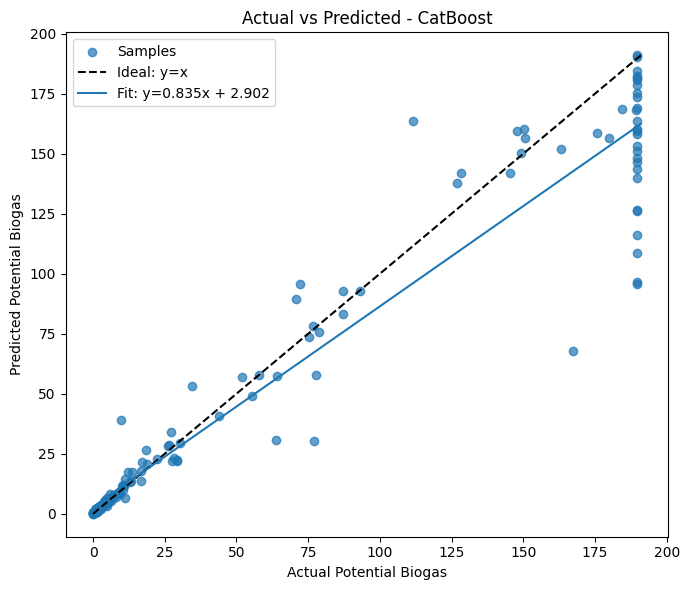


Calculating SHAP values...


/tmp/ipykernel_522/1874863752.py:135: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


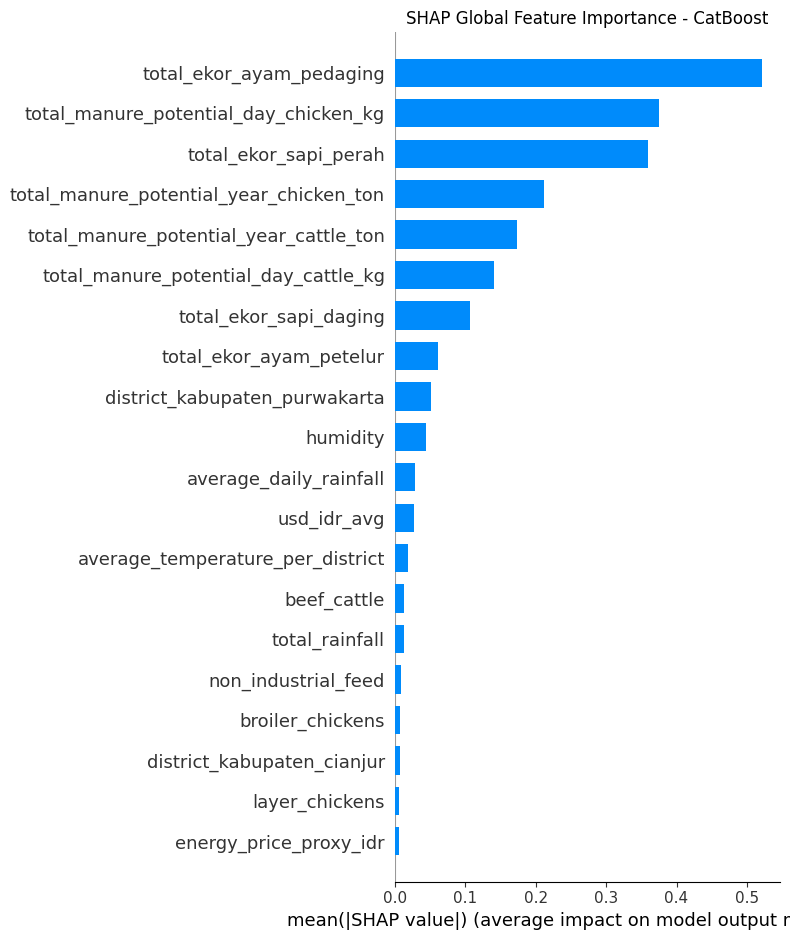

/tmp/ipykernel_522/1874863752.py:147: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


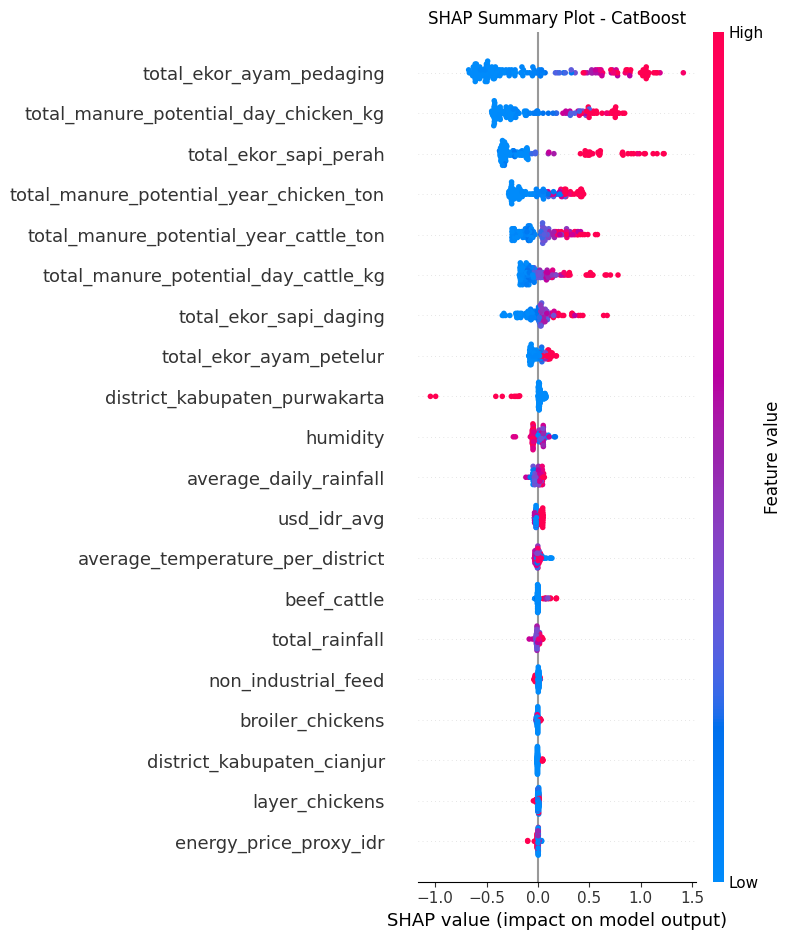


Calculating MDI...


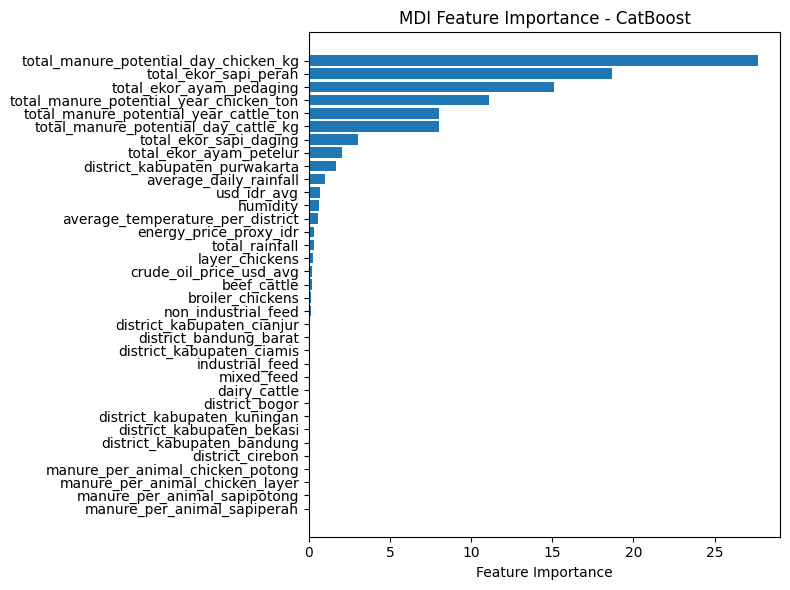


Calculating Permutation Importance - Test Set...


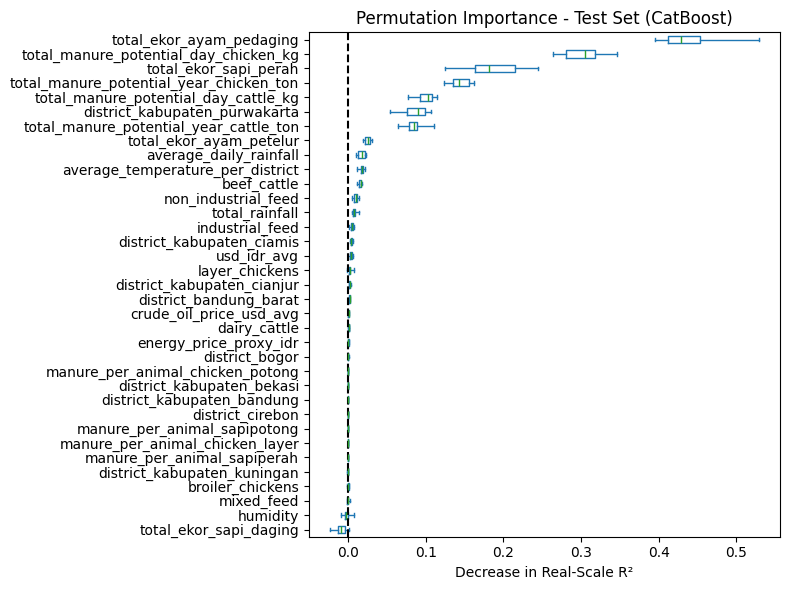


Calculating Permutation Importance - Train Set...


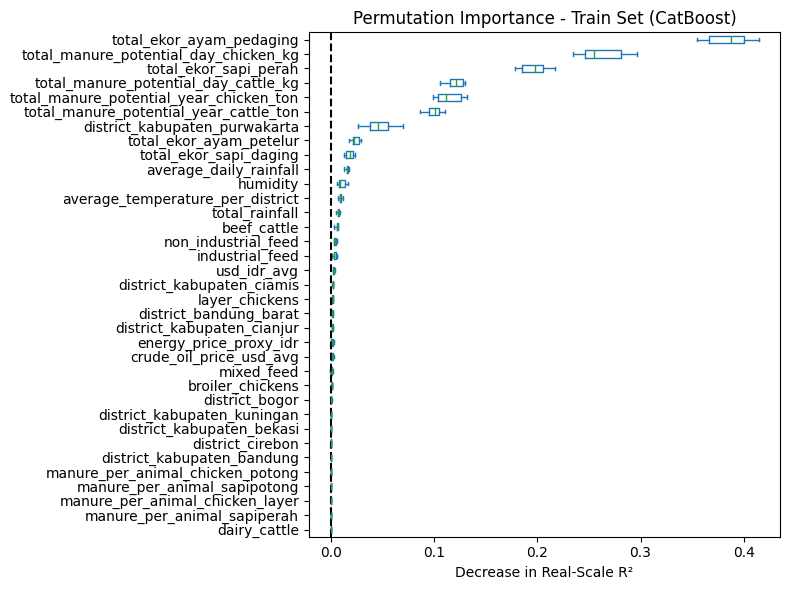


FINAL EVALUATION - CatBoost
Train R² : 0.9633
Test R²  : 0.9134
Test MSE : 479.9031
Test RMSE: 21.9067
Test MAE : 10.1158


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    make_scorer
)

# =========================================================
# 0. LOAD BEST MODEL HASIL PSO
# =========================================================

model_path = (
    "/content/drive/MyDrive/dataset/hasil_pso/"
    "best_overall_model.joblib"
)

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"File best model tidak ditemukan: {model_path}"
    )

best_model_bundle = joblib.load(model_path)

final_model = best_model_bundle["model"]
best_model_name = best_model_bundle["model_name"]
best_params = best_model_bundle["best_params"]
best_cv_r2 = best_model_bundle["cv_best_r2"]

print("=" * 60)
print("BEST MODEL HASIL PSO")
print("=" * 60)
print(f"Model       : {best_model_name}")
print(f"Best Params : {best_params}")
print(f"CV R²       : {best_cv_r2:.4f}")
print("=" * 60)


# =========================================================
# Helper: R² pada skala asli
# =========================================================

def r2_from_log_estimator(y_true_real, y_pred_log):
    y_pred_real = np.expm1(y_pred_log)
    return r2_score(y_true_real, y_pred_real)


real_r2_perm_scorer = make_scorer(
    r2_from_log_estimator,
    greater_is_better=True
)


# =========================================================
# 1. FINAL PREDICTION
# =========================================================

y_pred_log = final_model.predict(X_test)
y_pred = np.expm1(y_pred_log)

y_true = np.asarray(y_test_true)

# Pastikan prediksi dan target memiliki panjang yang sama
assert len(y_true) == len(y_pred), "Jumlah prediksi dan target tidak sama."


# =========================================================
# 2. ACTUAL vs PREDICTED + LINEAR FIT
# =========================================================

plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.7,
    label="Samples"
)

min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

# Ideal line
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "k--",
    label="Ideal: y=x"
)

# Linear fit
slope, intercept = np.polyfit(y_true, y_pred, 1)

x_line = np.linspace(min_val, max_val, 100)

plt.plot(
    x_line,
    slope * x_line + intercept,
    label=f"Fit: y={slope:.3f}x + {intercept:.3f}"
)

plt.xlabel("Actual Potential Biogas")
plt.ylabel("Predicted Potential Biogas")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# 3. SHAP EXPLAINABILITY
# =========================================================

print("\nCalculating SHAP values...")

# Menggunakan data training sebagai background
explainer = shap.Explainer(
    final_model,
    X_train
)

shap_values = explainer(
    X_test,
    check_additivity=False
)

# SHAP Global Feature Importance
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    show=False
)

plt.title(f"SHAP Global Feature Importance - {best_model_name}")
plt.tight_layout()
plt.show()

# SHAP Summary Plot
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title(f"SHAP Summary Plot - {best_model_name}")
plt.tight_layout()
plt.show()


# =========================================================
# 4. MDI (MEAN DECREASE IN IMPURITY)
# =========================================================

print("\nCalculating MDI...")

if hasattr(final_model, "feature_importances_"):

    mdi = final_model.feature_importances_

    features = np.asarray(X_train.columns)

    if len(mdi) != len(features):
        raise ValueError(
            "Jumlah feature importance tidak sesuai jumlah fitur."
        )

    idx = np.argsort(mdi)

    plt.figure(figsize=(8, 6))

    plt.barh(
        range(len(idx)),
        mdi[idx],
        tick_label=features[idx]
    )

    plt.xlabel("Feature Importance")
    plt.title(f"MDI Feature Importance - {best_model_name}")
    plt.tight_layout()
    plt.show()

else:
    print(
        f"{best_model_name} tidak memiliki "
        "feature_importances_. MDI tidak tersedia."
    )


# =========================================================
# 5. PERMUTATION IMPORTANCE - TEST SET
# =========================================================

print("\nCalculating Permutation Importance - Test Set...")

result_test = permutation_importance(
    final_model,
    X_test,
    y_test_true,
    n_repeats=10,
    random_state=42,
    n_jobs=1,
    scoring=real_r2_perm_scorer
)

sorted_idx_test = np.argsort(
    result_test.importances_mean
)

importances_test = pd.DataFrame(
    result_test.importances[sorted_idx_test].T,
    columns=X_test.columns[sorted_idx_test]
)

ax = importances_test.plot.box(
    vert=False,
    whis=10,
    figsize=(8, 6)
)

ax.set_title(
    f"Permutation Importance - Test Set ({best_model_name})"
)
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in Real-Scale R²")
ax.figure.tight_layout()
plt.show()


# =========================================================
# 6. PERMUTATION IMPORTANCE - TRAIN SET
# =========================================================

print("\nCalculating Permutation Importance - Train Set...")

result_train = permutation_importance(
    final_model,
    X_train,
    y_train_raw,
    n_repeats=10,
    random_state=42,
    n_jobs=1,
    scoring=real_r2_perm_scorer
)

sorted_idx_train = np.argsort(
    result_train.importances_mean
)

importances_train = pd.DataFrame(
    result_train.importances[sorted_idx_train].T,
    columns=X_train.columns[sorted_idx_train]
)

ax = importances_train.plot.box(
    vert=False,
    whis=10,
    figsize=(8, 6)
)

ax.set_title(
    f"Permutation Importance - Train Set ({best_model_name})"
)
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in Real-Scale R²")
ax.figure.tight_layout()
plt.show()


# =========================================================
# 7. TRAIN vs TEST EVALUATION - REAL SCALE
# =========================================================

train_pred_log = final_model.predict(X_train)
test_pred_log = final_model.predict(X_test)

train_pred_real = np.expm1(train_pred_log)
test_pred_real = np.expm1(test_pred_log)

train_r2 = r2_score(y_train_raw, train_pred_real)
test_r2 = r2_score(y_test_true, test_pred_real)

mse = mean_squared_error(y_test_true, test_pred_real)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_true, test_pred_real)

print("\n" + "=" * 60)
print(f"FINAL EVALUATION - {best_model_name}")
print("=" * 60)

print(f"Train R² : {train_r2:.4f}")
print(f"Test R²  : {test_r2:.4f}")
print(f"Test MSE : {mse:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE : {mae:.4f}")

print("=" * 60)
